In [3]:
%pip install xgboost

  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
Using cached xgboost-3.2.0-py3-none-win_amd64.whl (101.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import json
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

try:
    import xgboost
    from xgboost import XGBClassifier
except ImportError as error:
    raise ImportError(
        "XGBoost is not installed in this environment.\n"
        "Run  !pip install xgboost  in a new cell, restart the kernel, "
        "and run this notebook again."
    ) from error

# Locate the RiskLens project folder.
CURRENT = Path.cwd()

if CURRENT.name == "notebooks":
    ROOT = CURRENT.parent
elif CURRENT.name == "RiskLens":
    ROOT = CURRENT
else:
    raise ValueError(
        f"Current folder: {CURRENT}\n"
        "Please open this notebook from RiskLens/notebooks."
    )

DATA_FOLDER = ROOT / "data_processed"
R2_OUT = ROOT / "outputs" / "R2"
MODEL_DIR = ROOT / "models"

OUT = ROOT / "outputs" / "Midterm"
OUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)
print("Midterm outputs:", OUT)
print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgboost.__version__)

Project folder: C:\Users\tiwar\Documents\RiskLens
Midterm outputs: C:\Users\tiwar\Documents\RiskLens\outputs\Midterm
scikit-learn: 1.7.2 | XGBoost: 3.2.0


In [6]:

train = pd.read_csv(DATA_FOLDER / "banksim_train.csv")
validation = pd.read_csv(DATA_FOLDER / "banksim_validation.csv")

required_columns = ["transaction_id", "step", "amount", "category", "fraud"]

for name, frame in [("train", train), ("validation", validation)]:
    assert set(required_columns).issubset(frame.columns), f"{name}: missing columns."
    assert frame[required_columns].notna().all().all(), f"{name}: missing values."
    assert frame["transaction_id"].is_unique, f"{name}: duplicate IDs."
    assert set(frame["fraud"].unique()) == {0, 1}

assert set(train["step"].unique()) == set(range(108))
assert set(validation["step"].unique()) == set(range(108, 144))
assert set(train["transaction_id"]).isdisjoint(validation["transaction_id"])

FEATURES = ["amount", "category"]

X_train, y_train = train[FEATURES].copy(), train["fraud"].astype(int)
X_val, y_val = validation[FEATURES].copy(), validation["fraud"].astype(int)

print(f"Training rows:   {len(train):,}  (fraud: {int(y_train.sum()):,})")
print(f"Validation rows: {len(validation):,}  (fraud: {int(y_val.sum()):,})")
print("Predictors:", FEATURES)


Training rows:   332,592  (fraud: 4,320)
Validation rows: 128,820  (fraud: 1,440)
Predictors: ['amount', 'category']


In [7]:

def build_preprocessor():
    # Same preprocessing as the Logistic Regression in Progress Report 2.
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    category_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, ["amount"]),
        ("category", category_pipeline, ["category"])
    ], remainder="drop")


THRESHOLDS = np.linspace(0, 1, 101)


def threshold_table(y_true, scores):
    y = np.asarray(y_true).astype(bool)
    flagged = scores[:, None] >= THRESHOLDS[None, :]

    tp = (flagged & y[:, None]).sum(axis=0)
    fp = (flagged & ~y[:, None]).sum(axis=0)
    fn = y.sum() - tp

    precision = np.divide(
        tp, tp + fp, out=np.zeros(len(THRESHOLDS)), where=(tp + fp) > 0
    )
    recall = tp / y.sum()
    total = precision + recall
    f1 = np.divide(
        2 * precision * recall, total,
        out=np.zeros(len(THRESHOLDS)), where=total > 0
    )

    return pd.DataFrame({
        "threshold": THRESHOLDS,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": fp.astype(int),
        "false_negatives": fn.astype(int),
        "flagged_transactions": (tp + fp).astype(int)
    })


def select_threshold(table):
    ranked = table.sort_values(
        ["f1", "precision", "threshold"],
        ascending=[False, False, False]
    )
    return float(ranked.iloc[0]["threshold"])


def evaluate_at(name, y_true, scores, threshold, training_seconds=np.nan):
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "model": name,
        "partition": "validation",
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "average_precision": average_precision_score(y_true, scores),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
        "training_seconds": training_seconds
    }

print("Helpers ready.")

Helpers ready.


In [8]:

lr_pipeline = joblib.load(MODEL_DIR / "r2_logistic_regression_pipeline.joblib")
lr_scores = lr_pipeline.predict_proba(X_val)[:, 1]

r2_details = json.loads(
    (R2_OUT / "r2_lr_run_details.json").read_text(encoding="utf-8")
)
r2_metrics = pd.read_csv(R2_OUT / "r2_validation_model_metrics.csv")

saved_ap = r2_metrics.loc[
    r2_metrics["model"] == "Logistic Regression — selected threshold",
    "average_precision"
].iloc[0]

lr_table = threshold_table(y_val, lr_scores)
lr_threshold = select_threshold(lr_table)

assert np.isclose(average_precision_score(y_val, lr_scores), saved_ap), (
    "Reloaded Logistic Regression does not match Progress Report 2."
)
assert np.isclose(lr_threshold, r2_details["selected_threshold"]), (
    "Threshold rule does not reproduce the Progress Report 2 threshold."
)

lr_seconds = r2_details["training_seconds"]

print(f"PASS: Logistic Regression reproduced. AP = {saved_ap:.4f}, "
      f"threshold = {lr_threshold:.2f}")

PASS: Logistic Regression reproduced. AP = 0.7672, threshold = 0.98


In [9]:

neg_train = int((y_train == 0).sum())
pos_train = int((y_train == 1).sum())

RF_MIN_SAMPLES_LEAF = [10, 25, 50, 100]

rf_trials = []
rf_fitted = {}

for leaf in RF_MIN_SAMPLES_LEAF:
    pipeline = Pipeline([
        ("preprocessing", build_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=leaf,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ))
    ])

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    seconds = time.perf_counter() - start

    scores = pipeline.predict_proba(X_val)[:, 1]

    rf_trials.append({
        "model": "Random Forest",
        "setting": f"min_samples_leaf={leaf}",
        "validation_average_precision": average_precision_score(y_val, scores),
        "validation_roc_auc": roc_auc_score(y_val, scores),
        "training_seconds": seconds
    })
    rf_fitted[leaf] = (pipeline, scores, seconds)

rf_trials = pd.DataFrame(rf_trials)
display(rf_trials.round(4))

best_leaf = RF_MIN_SAMPLES_LEAF[
    int(rf_trials["validation_average_precision"].idxmax())
]
rf_pipeline, rf_scores, rf_seconds = rf_fitted[best_leaf]
del rf_fitted

print(f"Selected Random Forest setting: min_samples_leaf={best_leaf}")

,model,setting,validation_average_precision,validation_roc_auc,training_seconds
0,Random Forest,min_samples_leaf=10,0.7929,0.9919,33.8249
1,Random Forest,min_samples_leaf=25,0.8028,0.9925,30.8816
2,Random Forest,min_samples_leaf=50,0.8007,0.9926,30.4605
3,Random Forest,min_samples_leaf=100,0.7926,0.9927,30.3054


Selected Random Forest setting: min_samples_leaf=25


In [10]:
scale_pos_weight = neg_train / pos_train
print(f"scale_pos_weight (training only): {scale_pos_weight:.2f}")

XGB_MAX_DEPTH = [3, 4, 6]

xgb_trials = []
xgb_fitted = {}

for depth in XGB_MAX_DEPTH:
    pipeline = Pipeline([
        ("preprocessing", build_preprocessor()),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=depth,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        ))
    ])

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    seconds = time.perf_counter() - start

    scores = pipeline.predict_proba(X_val)[:, 1]

    xgb_trials.append({
        "model": "XGBoost",
        "setting": f"max_depth={depth}",
        "validation_average_precision": average_precision_score(y_val, scores),
        "validation_roc_auc": roc_auc_score(y_val, scores),
        "training_seconds": seconds
    })
    xgb_fitted[depth] = (pipeline, scores, seconds)

xgb_trials = pd.DataFrame(xgb_trials)
display(xgb_trials.round(4))

best_depth = XGB_MAX_DEPTH[
    int(xgb_trials["validation_average_precision"].idxmax())
]
xgb_pipeline, xgb_scores, xgb_seconds = xgb_fitted[best_depth]
del xgb_fitted

print(f"Selected XGBoost setting: max_depth={best_depth}")

scale_pos_weight (training only): 75.99


,model,setting,validation_average_precision,validation_roc_auc,training_seconds
0,XGBoost,max_depth=3,0.7870,0.9925,2.4922
1,XGBoost,max_depth=4,0.7957,0.9923,2.7197
2,XGBoost,max_depth=6,0.7945,0.9920,3.3247


Selected XGBoost setting: max_depth=4


In [11]:

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_scores = dummy.predict_proba(X_val)[:, 1]

models = {
    "Logistic Regression": {
        "pipeline": lr_pipeline, "scores": lr_scores, "seconds": lr_seconds,
        "setting": "class_weight=balanced, C=1.0 (Progress Report 2)"
    },
    "Random Forest": {
        "pipeline": rf_pipeline, "scores": rf_scores, "seconds": rf_seconds,
        "setting": f"300 trees, min_samples_leaf={best_leaf}, balanced_subsample"
    },
    "XGBoost": {
        "pipeline": xgb_pipeline, "scores": xgb_scores, "seconds": xgb_seconds,
        "setting": f"300 trees, max_depth={best_depth}, learning_rate=0.1, "
                   f"scale_pos_weight={scale_pos_weight:.1f}"
    }
}

rows = [evaluate_at("Always legitimate", y_val, dummy_scores, 0.50)]

for name, bundle in models.items():
    table = threshold_table(y_val, bundle["scores"])
    bundle["table"] = table
    bundle["threshold"] = select_threshold(table)
    bundle["predictions"] = (bundle["scores"] >= bundle["threshold"]).astype(int)

    rows.append(evaluate_at(
        f"{name} — default threshold", y_val, bundle["scores"], 0.50,
        bundle["seconds"]
    ))
    rows.append(evaluate_at(
        f"{name} — selected threshold", y_val, bundle["scores"],
        bundle["threshold"], bundle["seconds"]
    ))

comparison = pd.DataFrame(rows)

show = comparison[[
    "model", "threshold", "precision", "recall", "f1",
    "roc_auc", "average_precision",
    "false_positives", "false_negatives", "training_seconds"
]]
display(show.round(4))


,model,threshold,precision,recall,f1,roc_auc,average_precision,false_positives,false_negatives,training_seconds
0,Always legitimate,0.50,0.0000,0.0000,0.0000,0.5000,0.0112,0,1440,NaN
1,Logistic Regression — default threshold,0.50,0.1515,0.9757,0.2623,0.9924,0.7672,7869,35,0.4232
2,Logistic Regression — selected threshold,0.98,0.8179,0.6333,0.7139,0.9924,0.7672,203,528,0.4232
3,Random Forest — default threshold,0.50,0.2574,0.9083,0.4011,0.9925,0.8028,3774,132,30.8816
4,Random Forest — selected threshold,0.98,0.8917,0.6347,0.7416,0.9925,0.8028,111,526,30.8816
5,XGBoost — default threshold,0.50,0.1642,0.9514,0.2801,0.9923,0.7957,6973,70,2.7197
6,XGBoost — selected threshold,0.98,0.8544,0.6562,0.7423,0.9923,0.7957,161,495,2.7197


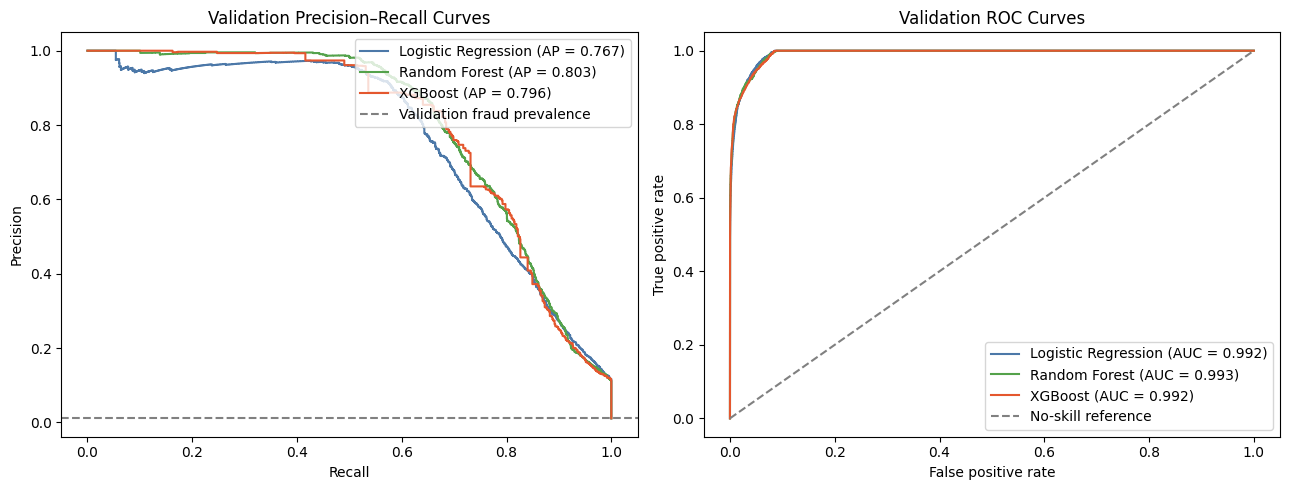

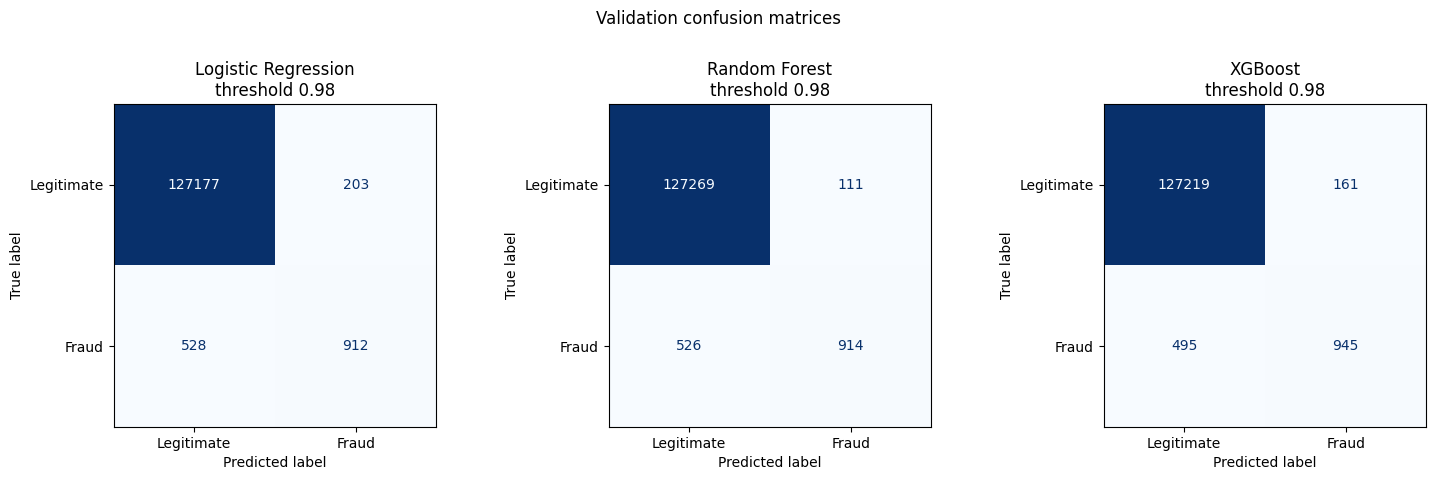

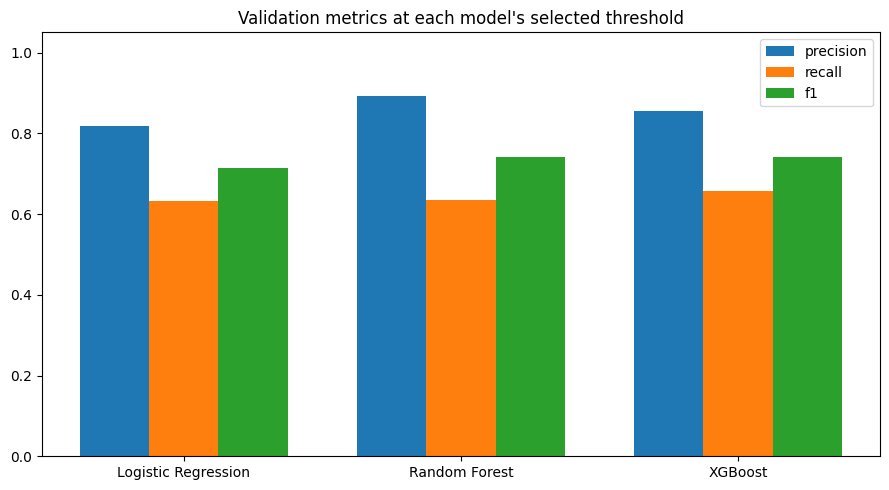

In [12]:

COLORS = {
    "Logistic Regression": "#4C78A8",
    "Random Forest": "#54A24B",
    "XGBoost": "#E4572E"
}

# 1) Precision-recall and ROC curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, bundle in models.items():
    precision, recall, _ = precision_recall_curve(y_val, bundle["scores"])
    fpr, tpr, _ = roc_curve(y_val, bundle["scores"])
    ap = average_precision_score(y_val, bundle["scores"])
    auc = roc_auc_score(y_val, bundle["scores"])

    axes[0].step(recall, precision, where="post", color=COLORS[name],
                 label=f"{name} (AP = {ap:.3f})")
    axes[1].plot(fpr, tpr, color=COLORS[name],
                 label=f"{name} (AUC = {auc:.3f})")

axes[0].axhline(y_val.mean(), linestyle="--", color="gray",
                label="Validation fraud prevalence")
axes[0].set_title("Validation Precision–Recall Curves")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc="upper right")

axes[1].plot([0, 1], [0, 1], "--", color="gray", label="No-skill reference")
axes[1].set_title("Validation ROC Curves")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig(OUT / "mid_curves_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# 2) Confusion matrices at each model's selected threshold
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

for ax, (name, bundle) in zip(axes, models.items()):
    matrix = confusion_matrix(y_val, bundle["predictions"], labels=[0, 1])
    ConfusionMatrixDisplay(
        matrix, display_labels=["Legitimate", "Fraud"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name}\nthreshold {bundle['threshold']:.2f}")

fig.suptitle("Validation confusion matrices", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "mid_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

# 3) Precision, recall, and F1 at the selected thresholds
selected = comparison[comparison["model"].str.endswith("selected threshold")].copy()
selected["short_name"] = selected["model"].str.replace(
    " — selected threshold", "", regex=False
)

fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(selected))
width = 0.25

for offset, metric in zip([-width, 0, width], ["precision", "recall", "f1"]):
    ax.bar(positions + offset, selected[metric], width, label=metric)

ax.set_xticks(positions)
ax.set_xticklabels(selected["short_name"])
ax.set_ylim(0, 1.05)
ax.set_title("Validation metrics at each model's selected threshold")
ax.legend()

fig.tight_layout()
fig.savefig(OUT / "mid_metrics_bar.png", dpi=200, bbox_inches="tight")
plt.show()

,model,feature,ap_drop_mean,ap_drop_std
0,Logistic Regression,amount,0.4626,0.0029
1,Logistic Regression,category,0.5833,0.0074
2,Random Forest,amount,0.5393,0.0035
3,Random Forest,category,0.6706,0.0088
4,XGBoost,amount,0.5095,0.0039
5,XGBoost,category,0.7032,0.0074


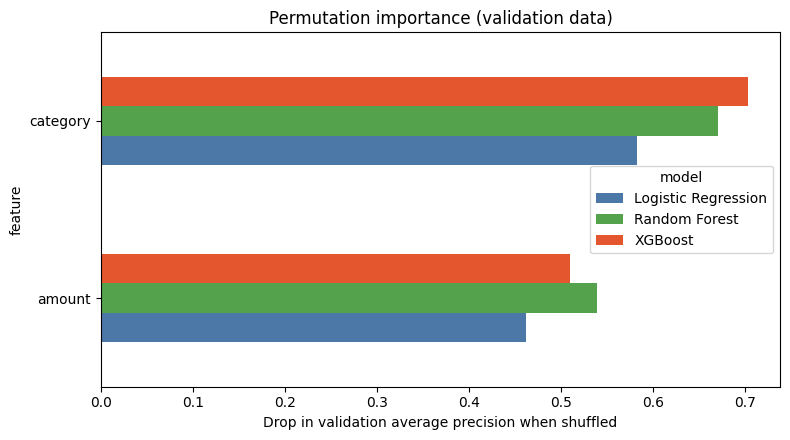

,feature,coefficient
9,es_leisure,4.312
11,es_sportsandtoys,3.142
7,es_hotelservices,2.197
14,es_travel,2.128
10,es_otherservices,2.011
0,amount,1.529
5,es_health,1.172
6,es_home,1.128
8,es_hyper,0.759
15,es_wellnessandbeauty,0.743


In [13]:

importance_rows = []

for name, bundle in models.items():
    result = permutation_importance(
        bundle["pipeline"], X_val, y_val,
        scoring="average_precision",
        n_repeats=5,
        random_state=42,
        n_jobs=1
    )
    for index, feature in enumerate(FEATURES):
        importance_rows.append({
            "model": name,
            "feature": feature,
            "ap_drop_mean": result.importances_mean[index],
            "ap_drop_std": result.importances_std[index]
        })

importance = pd.DataFrame(importance_rows)
display(importance.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot = importance.pivot(index="feature", columns="model", values="ap_drop_mean")
pivot[list(models)].plot.barh(
    ax=ax, color=[COLORS[name] for name in models]
)
ax.set_xlabel("Drop in validation average precision when shuffled")
ax.set_title("Permutation importance (validation data)")
fig.tight_layout()
fig.savefig(OUT / "mid_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

# Logistic Regression coefficients (log-odds; positive = higher fraud score)
lr_names = lr_pipeline.named_steps["preprocessing"].get_feature_names_out()
lr_coefficients = pd.DataFrame({
    "feature": [
        n.replace("numeric__", "").replace("category__category_", "")
        for n in lr_names
    ],
    "coefficient": lr_pipeline.named_steps["classifier"].coef_[0]
}).sort_values("coefficient", ascending=False)

display(lr_coefficients.round(3))

In [14]:

category_frames = []

for name, bundle in models.items():
    frame = validation[["category", "fraud"]].copy()
    frame["predicted"] = bundle["predictions"]

    frame["tp"] = ((frame["fraud"] == 1) & (frame["predicted"] == 1)).astype(int)
    frame["fp"] = ((frame["fraud"] == 0) & (frame["predicted"] == 1)).astype(int)
    frame["fn"] = ((frame["fraud"] == 1) & (frame["predicted"] == 0)).astype(int)
    frame["tn"] = ((frame["fraud"] == 0) & (frame["predicted"] == 0)).astype(int)

    summary = frame.groupby("category")[["tp", "fp", "fn", "tn"]].sum().reset_index()
    summary.insert(0, "model", name)
    summary["transactions"] = summary[["tp", "fp", "fn", "tn"]].sum(axis=1)
    summary["fraud_transactions"] = summary["tp"] + summary["fn"]
    summary["flagged_transactions"] = summary["tp"] + summary["fp"]
    summary["recall"] = np.where(
        summary["fraud_transactions"] > 0,
        summary["tp"] / summary["fraud_transactions"].replace(0, np.nan), np.nan
    )
    summary["precision"] = np.where(
        summary["flagged_transactions"] > 0,
        summary["tp"] / summary["flagged_transactions"].replace(0, np.nan), np.nan
    )
    category_frames.append(summary)

category_results = pd.concat(category_frames, ignore_index=True)

display(
    category_results[category_results["fraud_transactions"] > 0]
    .pivot(index="category", columns="model", values="fn")
    .assign(fraud_in_category=lambda d: (
        category_results[category_results["model"] == "Logistic Regression"]
        .set_index("category")["fraud_transactions"]
    ))
    .sort_values("fraud_in_category", ascending=False)
    .rename_axis(columns=None)
)
print("Table above: missed fraud (false negatives) by category and model.")

,Logistic Regression,Random Forest,XGBoost,fraud_in_category
category,,,,
es_sportsandtoys,102,141,129,402
es_health,142,147,144,346
es_wellnessandbeauty,94,71,75,132
es_hotelservices,32,35,33,122
es_travel,7,19,8,122
es_leisure,1,9,2,82
es_hyper,56,27,27,64
es_otherservices,16,15,15,48
es_home,17,17,17,38


Table above: missed fraud (false negatives) by category and model.


In [15]:

# Model comparison and settings
comparison.to_csv(OUT / "mid_model_comparison.csv", index=False)
pd.concat([rf_trials, xgb_trials]).to_csv(OUT / "mid_validation_grid.csv", index=False)

# Threshold curves for all models (long format for Power BI)
pd.concat(
    [bundle["table"].assign(model=name) for name, bundle in models.items()],
    ignore_index=True
).to_csv(OUT / "mid_threshold_curves.csv", index=False)

# Importance and category results
importance.to_csv(OUT / "mid_permutation_importance.csv", index=False)
lr_coefficients.to_csv(OUT / "mid_lr_coefficients.csv", index=False)
category_results.to_csv(OUT / "mid_category_results.csv", index=False)

# Transaction-level validation predictions, one row per transaction per model
prediction_frames = []

for name, bundle in models.items():
    frame = validation[
        ["transaction_id", "step", "amount", "category", "fraud"]
    ].rename(columns={"fraud": "actual_fraud"}).copy()

    frame["model"] = name
    frame["model_score"] = bundle["scores"]
    frame["threshold"] = bundle["threshold"]
    frame["predicted_fraud"] = bundle["predictions"]
    frame["outcome"] = np.select(
        [
            (frame["actual_fraud"] == 1) & (frame["predicted_fraud"] == 1),
            (frame["actual_fraud"] == 0) & (frame["predicted_fraud"] == 1),
            (frame["actual_fraud"] == 1) & (frame["predicted_fraud"] == 0)
        ],
        ["True positive", "False positive", "False negative"],
        default="True negative"
    )
    frame["partition"] = "validation"
    prediction_frames.append(frame)

pd.concat(prediction_frames, ignore_index=True).to_csv(
    OUT / "mid_validation_predictions_all_models.csv",
    index=False, float_format="%.6f"
)

# Fitted models
joblib.dump(rf_pipeline, MODEL_DIR / "mid_random_forest_pipeline.joblib", compress=3)
joblib.dump(xgb_pipeline, MODEL_DIR / "mid_xgboost_pipeline.joblib", compress=3)

# Settings and selection rules, so the run can be explained and reproduced
run_details = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "BankSim synthetic transactions",
    "features": FEATURES,
    "target": "fraud",
    "training_steps": [0, 107],
    "validation_steps": [108, 143],
    "reserved_test_steps": [144, 179],
    "models": {
        name: {
            "setting": bundle["setting"],
            "selected_threshold": bundle["threshold"],
            "training_seconds": bundle["seconds"]
        }
        for name, bundle in models.items()
    },
    "setting_selection_rule": "Highest validation average precision",
    "threshold_rule": (
        "Maximum validation F1 on thresholds 0.00-1.00 in steps of 0.01; "
        "ties: higher precision, then higher threshold."
    ),
    "logistic_regression_source": "Reloaded from Progress Report 2 (not retrained)",
    "permutation_importance": "average_precision on validation, 5 repeats, seed 42",
    "random_state": 42,
    "test_evaluated": False,
    "calibration_performed": False,
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__
}

(OUT / "mid_run_details.json").write_text(
    json.dumps(run_details, indent=2), encoding="utf-8"
)

print("Saved results to:", OUT)
print("Saved models to:", MODEL_DIR)

Saved results to: C:\Users\tiwar\Documents\RiskLens\outputs\Midterm
Saved models to: C:\Users\tiwar\Documents\RiskLens\models


In [17]:

expected = [
    "mid_model_comparison.csv", "mid_validation_grid.csv",
    "mid_threshold_curves.csv", "mid_permutation_importance.csv",
    "mid_lr_coefficients.csv", "mid_category_results.csv",
    "mid_validation_predictions_all_models.csv", "mid_run_details.json",
    "mid_curves_comparison.png", "mid_confusion_matrices.png",
    "mid_metrics_bar.png", "mid_permutation_importance.png"
]

missing = [name for name in expected if not (OUT / name).is_file()]
assert not missing, f"Missing outputs: {missing}"

predictions_check = pd.read_csv(OUT / "mid_validation_predictions_all_models.csv")
assert len(predictions_check) == 3 * len(validation)

# Saved predictions must reproduce the comparison table.
for name in models:
    block = predictions_check[predictions_check["model"] == name]
    row = comparison[comparison["model"] == f"{name} — selected threshold"].iloc[0]
    assert (block["outcome"] == "False negative").sum() == row["false_negatives"]
    assert (block["outcome"] == "False positive").sum() == row["false_positives"]
    assert (block["outcome"] == "True positive").sum() == row["true_positives"]

display(show[show["model"].str.endswith("selected threshold")].round(4))

print("PASS: all outputs saved and consistent.")
print("Test-set evaluation has NOT been performed.")
print("Save this notebook.")

,model,threshold,precision,recall,f1,roc_auc,average_precision,false_positives,false_negatives,training_seconds
2,Logistic Regression — selected threshold,0.98,0.8179,0.6333,0.7139,0.9924,0.7672,203,528,0.4232
4,Random Forest — selected threshold,0.98,0.8917,0.6347,0.7416,0.9925,0.8028,111,526,30.8816
6,XGBoost — selected threshold,0.98,0.8544,0.6562,0.7423,0.9923,0.7957,161,495,2.7197


PASS: all outputs saved and consistent.
Test-set evaluation has NOT been performed.
Save this notebook.
